In [44]:
print("Welcome to my UK Care Service Performance Analysis project")

Welcome to my UK Care Service Performance Analysis project


In [45]:
import pandas as pd

In [46]:
df = pd.read_csv("uk_care_service_performance_synthetic.csv")

In [47]:
df.head()

,record_id,service_date,month,service_location,service_users_supported,scheduled_visits,completed_visits,missed_visits,delayed_visits,staff_scheduled_hours,staff_absence_hours,staff_worked_hours,staff_attendance_rate_pct,incident_reports,service_user_satisfaction_score
0,CSR0001,2025-01-02,2025-01,Northampton Central,57,83,82,1,4,181.261759,4.7,176.6,97.4,0,4.6
1,CSR0002,2025-01-02,2025-01,Northampton East,53,80,76,4,7,156.985035,6.5,150.5,95.9,2,4.1
2,CSR0003,2025-01-02,2025-01,Northampton West,27,25,23,2,1,149.782126,20.7,129.1,86.2,0,4.2
3,CSR0004,2025-01-02,2025-01,Wellingborough,50,75,72,3,8,183.713129,2.5,181.2,98.6,0,4.6
4,CSR0005,2025-01-02,2025-01,Kettering,38,68,68,0,1,168.681603,5.6,163.1,96.7,0,4.8


In [48]:
df.shape

(1000, 15)

In [49]:
df.columns

Index(['record_id', 'service_date', 'month', 'service_location',
       'service_users_supported', 'scheduled_visits', 'completed_visits',
       'missed_visits', 'delayed_visits', 'staff_scheduled_hours',
       'staff_absence_hours', 'staff_worked_hours',
       'staff_attendance_rate_pct', 'incident_reports',
       'service_user_satisfaction_score'],
      dtype='object')

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   record_id                        1000 non-null   object 
 1   service_date                     1000 non-null   object 
 2   month                            1000 non-null   object 
 3   service_location                 1000 non-null   object 
 4   service_users_supported          1000 non-null   int64  
 5   scheduled_visits                 1000 non-null   int64  
 6   completed_visits                 1000 non-null   int64  
 7   missed_visits                    1000 non-null   int64  
 8   delayed_visits                   1000 non-null   int64  
 9   staff_scheduled_hours            1000 non-null   float64
 10  staff_absence_hours              1000 non-null   float64
 11  staff_worked_hours               1000 non-null   float64
 12  staff_attendance_rate

In [51]:
df.isnull().sum()

,0
record_id,0
service_date,0
month,0
service_location,0
service_users_supported,0
scheduled_visits,0
completed_visits,0
missed_visits,0
delayed_visits,0
staff_scheduled_hours,0


In [52]:
df.duplicated().sum()

np.int64(0)

In [53]:
total_missed_visits = df["missed_visits"].sum()

total_scheduled_visits = df["scheduled_visits"].sum()

missed_visit_rate = total_missed_visits / total_scheduled_visits

print("Missed visit rate:", missed_visit_rate)

Missed visit rate: 0.026211058554885012


In [54]:
total_delayed_visits = df["delayed_visits"].sum()

total_completed_visits = df["completed_visits"].sum()

delayed_visit_rate = total_delayed_visits / total_completed_visits

print("Delayed visit rate:", delayed_visit_rate)

Delayed visit rate: 0.06528985143125136


In [55]:
total_staff_worked_hours = df["staff_worked_hours"].sum()

total_staff_scheduled_hours = df["staff_scheduled_hours"].sum()

staff_attendance_rate = total_staff_worked_hours / total_staff_scheduled_hours

print("Staff attendance rate:", staff_attendance_rate)

Staff attendance rate: 0.9686650745242064


In [56]:
total_incidents = df["incident_reports"].sum()

print("Total incident reports:", total_incidents)

Total incident reports: 870


In [57]:
average_satisfaction = df["service_user_satisfaction_score"].mean()

print("Average satisfaction:", average_satisfaction)

Average satisfaction: 4.399385245901638


In [58]:
kpi_summary = pd.DataFrame({
    "Performance Indicator": [
        "Missed visit rate",
        "Delayed visit rate",
        "Staff attendance",
        "Total incident reports",
        "Average satisfaction"
    ],
    "Result": [
        f"{missed_visit_rate:.1%}",
        f"{delayed_visit_rate:.1%}",
        f"{staff_attendance_rate:.1%}",
        f"{total_incidents:,}",
        f"{average_satisfaction:.3f} / 5"
    ]
})

display(kpi_summary)

,Performance Indicator,Result
0,Missed visit rate,2.6%
1,Delayed visit rate,6.5%
2,Staff attendance,96.9%
3,Total incident reports,870
4,Average satisfaction,4.399 / 5


In [59]:
df["service_location"].value_counts()

,count
service_location,
Northampton Central,100
Northampton East,100
Northampton West,100
Wellingborough,100
Kettering,100
Corby,100
Daventry,100
Towcester,100
Milton Keynes North,100


In [60]:
location_performance = df.groupby("service_location").agg(
    total_scheduled_visits=("scheduled_visits", "sum"),
    total_missed_visits=("missed_visits", "sum")
)

location_performance["missed_visit_rate"] = (
    location_performance["total_missed_visits"] /
    location_performance["total_scheduled_visits"]
)

display(location_performance)

,total_scheduled_visits,total_missed_visits,missed_visit_rate
service_location,,,
Corby,6142,180,0.029306
Daventry,6150,150,0.024390
Kettering,6147,129,0.020986
Milton Keynes North,5900,178,0.030169
Milton Keynes South,5788,141,0.024361
Northampton Central,6157,192,0.031184
Northampton East,6214,161,0.025909
Northampton West,6158,140,0.022735
Towcester,6435,162,0.025175


In [61]:
location_ranking = location_performance.sort_values(
    by="missed_visit_rate",
    ascending=False
)

display(location_ranking)

,total_scheduled_visits,total_missed_visits,missed_visit_rate
service_location,,,
Northampton Central,6157,192,0.031184
Milton Keynes North,5900,178,0.030169
Corby,6142,180,0.029306
Wellingborough,6219,174,0.027979
Northampton East,6214,161,0.025909
Towcester,6435,162,0.025175
Daventry,6150,150,0.024390
Milton Keynes South,5788,141,0.024361
Northampton West,6158,140,0.022735


In [62]:
location_ranking["missed_visit_rate"] = (
    location_ranking["missed_visit_rate"] * 100
).round(2)

display(location_ranking)

,total_scheduled_visits,total_missed_visits,missed_visit_rate
service_location,,,
Northampton Central,6157,192,3.12
Milton Keynes North,5900,178,3.02
Corby,6142,180,2.93
Wellingborough,6219,174,2.80
Northampton East,6214,161,2.59
Towcester,6435,162,2.52
Daventry,6150,150,2.44
Milton Keynes South,5788,141,2.44
Northampton West,6158,140,2.27


In [63]:
highest_rate = location_ranking["missed_visit_rate"].max()

lowest_rate = location_ranking["missed_visit_rate"].min()

print("Highest missed-visit rate:", highest_rate, "%")
print("Lowest missed-visit rate:", lowest_rate, "%")

Highest missed-visit rate: 3.12 %
Lowest missed-visit rate: 2.1 %


In [64]:
print("Highest:")
display(location_ranking.head(1))

print("Lowest:")
display(location_ranking.tail(1))

Highest:


,total_scheduled_visits,total_missed_visits,missed_visit_rate
service_location,,,
Northampton Central,6157,192,3.12


Lowest:


,total_scheduled_visits,total_missed_visits,missed_visit_rate
service_location,,,
Kettering,6147,129,2.1


In [65]:
location_ranking

,total_scheduled_visits,total_missed_visits,missed_visit_rate
service_location,,,
Northampton Central,6157,192,3.12
Milton Keynes North,5900,178,3.02
Corby,6142,180,2.93
Wellingborough,6219,174,2.80
Northampton East,6214,161,2.59
Towcester,6435,162,2.52
Daventry,6150,150,2.44
Milton Keynes South,5788,141,2.44
Northampton West,6158,140,2.27


In [66]:
location_delays = df.groupby("service_location").agg(
    total_completed_visits=("completed_visits", "sum"),
    total_delayed_visits=("delayed_visits", "sum")
)

location_delays["delayed_visit_rate"] = (
    location_delays["total_delayed_visits"] /
    location_delays["total_completed_visits"]
) * 100

location_delays["delayed_visit_rate"] = (
    location_delays["delayed_visit_rate"].round(2)
)

display(location_delays.sort_values(
    by="delayed_visit_rate",
    ascending=False
))

,total_completed_visits,total_delayed_visits,delayed_visit_rate
service_location,,,
Wellingborough,6045,435,7.20
Milton Keynes North,5722,396,6.92
Milton Keynes South,5647,380,6.73
Northampton Central,5965,397,6.66
Northampton West,6018,394,6.55
Towcester,6273,406,6.47
Kettering,6018,389,6.46
Northampton East,6053,381,6.29
Daventry,6000,364,6.07


In [67]:
location_staff = df.groupby("service_location").agg(
    total_scheduled_hours=("staff_scheduled_hours", "sum"),
    total_worked_hours=("staff_worked_hours", "sum")
)

location_staff["staff_attendance_rate"] = (
    location_staff["total_worked_hours"] /
    location_staff["total_scheduled_hours"]
) * 100

location_staff["staff_attendance_rate"] = (
    location_staff["staff_attendance_rate"].round(2)
)

display(location_staff.sort_values(
    by="staff_attendance_rate",
    ascending=True
))

,total_scheduled_hours,total_worked_hours,staff_attendance_rate
service_location,,,
Northampton Central,16615.703390,15977.7,96.16
Milton Keynes North,16455.330692,15841.5,96.27
Wellingborough,15894.360554,15342.0,96.52
Corby,16811.694356,16264.8,96.75
Daventry,16381.849758,15861.0,96.82
Milton Keynes South,17045.905066,16531.5,96.98
Northampton East,16837.975144,16347.2,97.09
Towcester,17136.110147,16669.4,97.28
Northampton West,16085.487273,15662.2,97.37


In [68]:
import matplotlib.pyplot as plt

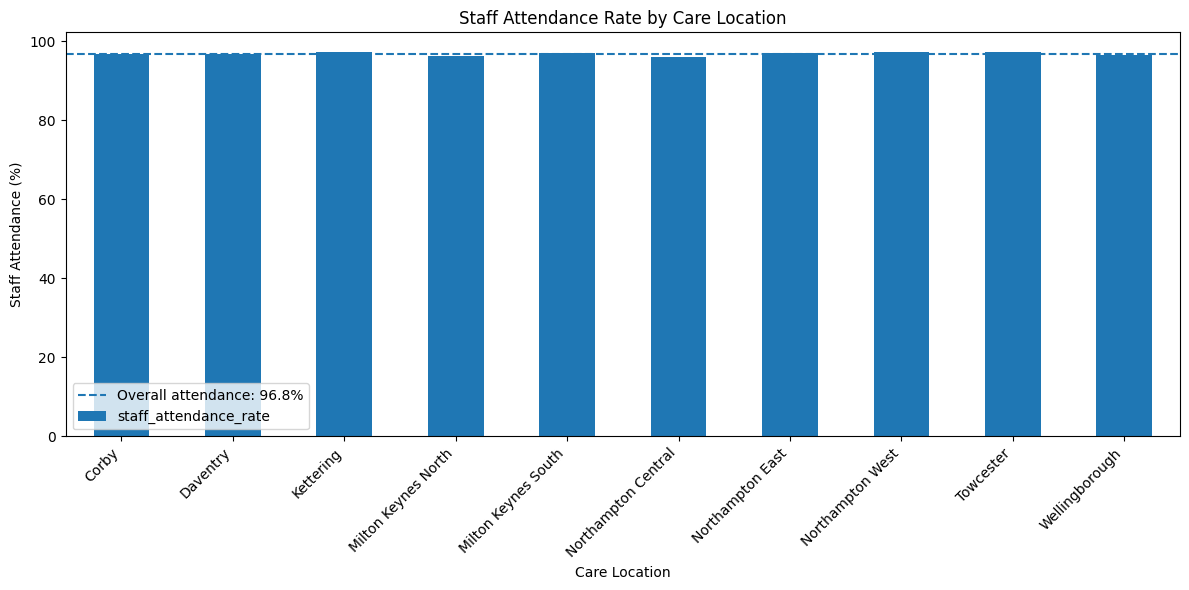

In [69]:
location_staff["staff_attendance_rate"].plot(
    kind="bar",
    figsize=(12, 6),
    title="Staff Attendance Rate by Care Location",
    ylabel="Staff Attendance (%)",
    xlabel="Care Location"
)

plt.xticks(rotation=45, ha="right")
plt.axhline(y=96.8, linestyle="--", label="Overall attendance: 96.8%")
plt.legend()
plt.tight_layout()
plt.show()

In [70]:
location_report = location_performance.join(
    location_delays
).join(
    location_staff
)

display(location_report)

,total_scheduled_visits,total_missed_visits,missed_visit_rate,total_completed_visits,total_delayed_visits,delayed_visit_rate,total_scheduled_hours,total_worked_hours,staff_attendance_rate
service_location,,,,,,,,,
Corby,6142,180,0.029306,5962,356,5.97,16811.694356,16264.8,96.75
Daventry,6150,150,0.024390,6000,364,6.07,16381.849758,15861.0,96.82
Kettering,6147,129,0.020986,6018,389,6.46,16385.615008,15962.1,97.42
Milton Keynes North,5900,178,0.030169,5722,396,6.92,16455.330692,15841.5,96.27
Milton Keynes South,5788,141,0.024361,5647,380,6.73,17045.905066,16531.5,96.98
Northampton Central,6157,192,0.031184,5965,397,6.66,16615.703390,15977.7,96.16
Northampton East,6214,161,0.025909,6053,381,6.29,16837.975144,16347.2,97.09
Northampton West,6158,140,0.022735,6018,394,6.55,16085.487273,15662.2,97.37
Towcester,6435,162,0.025175,6273,406,6.47,17136.110147,16669.4,97.28


In [71]:
top_5_locations = location_report.sort_values(
    by="missed_visit_rate",
    ascending=False
).head(5)

display(top_5_locations)

,total_scheduled_visits,total_missed_visits,missed_visit_rate,total_completed_visits,total_delayed_visits,delayed_visit_rate,total_scheduled_hours,total_worked_hours,staff_attendance_rate
service_location,,,,,,,,,
Northampton Central,6157,192,0.031184,5965,397,6.66,16615.703390,15977.7,96.16
Milton Keynes North,5900,178,0.030169,5722,396,6.92,16455.330692,15841.5,96.27
Corby,6142,180,0.029306,5962,356,5.97,16811.694356,16264.8,96.75
Wellingborough,6219,174,0.027979,6045,435,7.20,15894.360554,15342.0,96.52
Northampton East,6214,161,0.025909,6053,381,6.29,16837.975144,16347.2,97.09


In [72]:
df["service_date"] = pd.to_datetime(df["service_date"])

df["service_month"] = df["service_date"].dt.to_period("M").astype(str)

print(df[["service_date", "service_month"]].head())

  service_date service_month
0   2025-01-02       2025-01
1   2025-01-02       2025-01
2   2025-01-02       2025-01
3   2025-01-02       2025-01
4   2025-01-02       2025-01


In [73]:
monthly_performance = df.groupby("service_month").agg(
    scheduled_visits=("scheduled_visits", "sum"),
    completed_visits=("completed_visits", "sum"),
    missed_visits=("missed_visits", "sum"),
    delayed_visits=("delayed_visits", "sum"),
    scheduled_hours=("staff_scheduled_hours", "sum"),
    worked_hours=("staff_worked_hours", "sum"),
    incident_reports=("incident_reports", "sum"),
    average_satisfaction=("service_user_satisfaction_score", "mean")
)

monthly_performance["missed_visit_rate"] = (
    monthly_performance["missed_visits"] /
    monthly_performance["scheduled_visits"] * 100
).round(2)

monthly_performance["delayed_visit_rate"] = (
    monthly_performance["delayed_visits"] /
    monthly_performance["completed_visits"] * 100
).round(2)

monthly_performance["staff_attendance_rate"] = (
    monthly_performance["worked_hours"] /
    monthly_performance["scheduled_hours"] * 100
).round(2)

display(monthly_performance)

,scheduled_visits,completed_visits,missed_visits,delayed_visits,scheduled_hours,worked_hours,incident_reports,average_satisfaction,missed_visit_rate,delayed_visit_rate,staff_attendance_rate
service_month,,,,,,,,,,,
2025-01,4557,4432,125,275,11596.912819,11196.7,63,4.364286,2.74,6.20,96.55
2025-02,6340,6170,170,418,17365.140770,16833.5,96,4.415686,2.68,6.77,96.94
2025-03,4433,4320,113,295,12229.452523,11876.1,70,4.442029,2.55,6.83,97.11
2025-04,5018,4902,116,310,13574.927514,13170.2,55,4.470513,2.31,6.32,97.02
2025-05,3343,3258,85,224,9589.294713,9261.4,41,4.366102,2.54,6.88,96.58
2025-06,6075,5925,150,373,16283.753076,15770.1,87,4.447872,2.47,6.30,96.85
2025-07,5386,5227,159,351,15077.685676,14591.2,79,4.416471,2.95,6.72,96.77
2025-08,5149,5006,143,349,13835.173992,13418.6,74,4.368605,2.78,6.97,96.99
2025-09,5153,5017,136,314,13529.006463,13091.2,83,4.335802,2.64,6.26,96.76


In [74]:
monthly_performance = df.groupby("service_month").agg(
    scheduled_visits=("scheduled_visits", "sum"),
    completed_visits=("completed_visits", "sum"),
    missed_visits=("missed_visits", "sum"),
    delayed_visits=("delayed_visits", "sum"),
    scheduled_hours=("staff_scheduled_hours", "sum"),
    worked_hours=("staff_worked_hours", "sum"),
    incident_reports=("incident_reports", "sum"),
    average_satisfaction=("service_user_satisfaction_score", "mean")
)

monthly_performance["missed_visit_rate"] = (
    monthly_performance["missed_visits"] /
    monthly_performance["scheduled_visits"] * 100
).round(2)

monthly_performance["delayed_visit_rate"] = (
    monthly_performance["delayed_visits"] /
    monthly_performance["completed_visits"] * 100
).round(2)

monthly_performance["staff_attendance_rate"] = (
    monthly_performance["worked_hours"] /
    monthly_performance["scheduled_hours"] * 100
).round(2)

display(monthly_performance)

,scheduled_visits,completed_visits,missed_visits,delayed_visits,scheduled_hours,worked_hours,incident_reports,average_satisfaction,missed_visit_rate,delayed_visit_rate,staff_attendance_rate
service_month,,,,,,,,,,,
2025-01,4557,4432,125,275,11596.912819,11196.7,63,4.364286,2.74,6.20,96.55
2025-02,6340,6170,170,418,17365.140770,16833.5,96,4.415686,2.68,6.77,96.94
2025-03,4433,4320,113,295,12229.452523,11876.1,70,4.442029,2.55,6.83,97.11
2025-04,5018,4902,116,310,13574.927514,13170.2,55,4.470513,2.31,6.32,97.02
2025-05,3343,3258,85,224,9589.294713,9261.4,41,4.366102,2.54,6.88,96.58
2025-06,6075,5925,150,373,16283.753076,15770.1,87,4.447872,2.47,6.30,96.85
2025-07,5386,5227,159,351,15077.685676,14591.2,79,4.416471,2.95,6.72,96.77
2025-08,5149,5006,143,349,13835.173992,13418.6,74,4.368605,2.78,6.97,96.99
2025-09,5153,5017,136,314,13529.006463,13091.2,83,4.335802,2.64,6.26,96.76


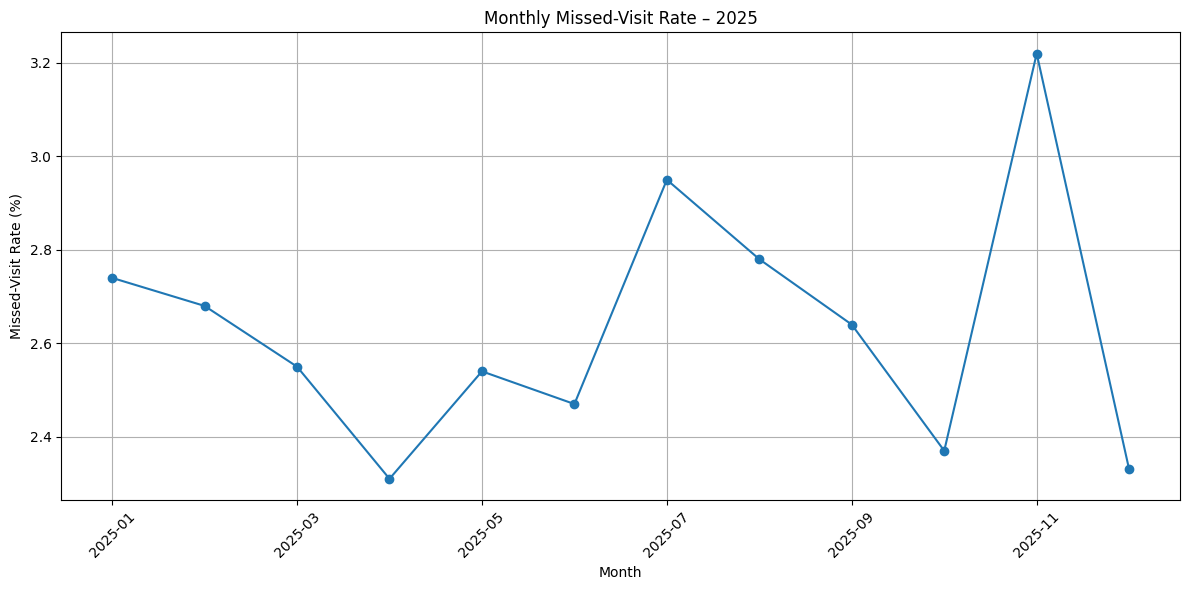

In [75]:
monthly_performance["missed_visit_rate"].plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
    title="Monthly Missed-Visit Rate – 2025",
    ylabel="Missed-Visit Rate (%)",
    xlabel="Month"
)

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [76]:
highest_month = monthly_performance["missed_visit_rate"].idxmax()
lowest_month = monthly_performance["missed_visit_rate"].idxmin()

print("Highest missed-visit month:", highest_month)
print("Highest rate:", monthly_performance.loc[highest_month, "missed_visit_rate"], "%")

print("Lowest missed-visit month:", lowest_month)
print("Lowest rate:", monthly_performance.loc[lowest_month, "missed_visit_rate"], "%")

Highest missed-visit month: 2025-11
Highest rate: 3.22 %
Lowest missed-visit month: 2025-04
Lowest rate: 2.31 %


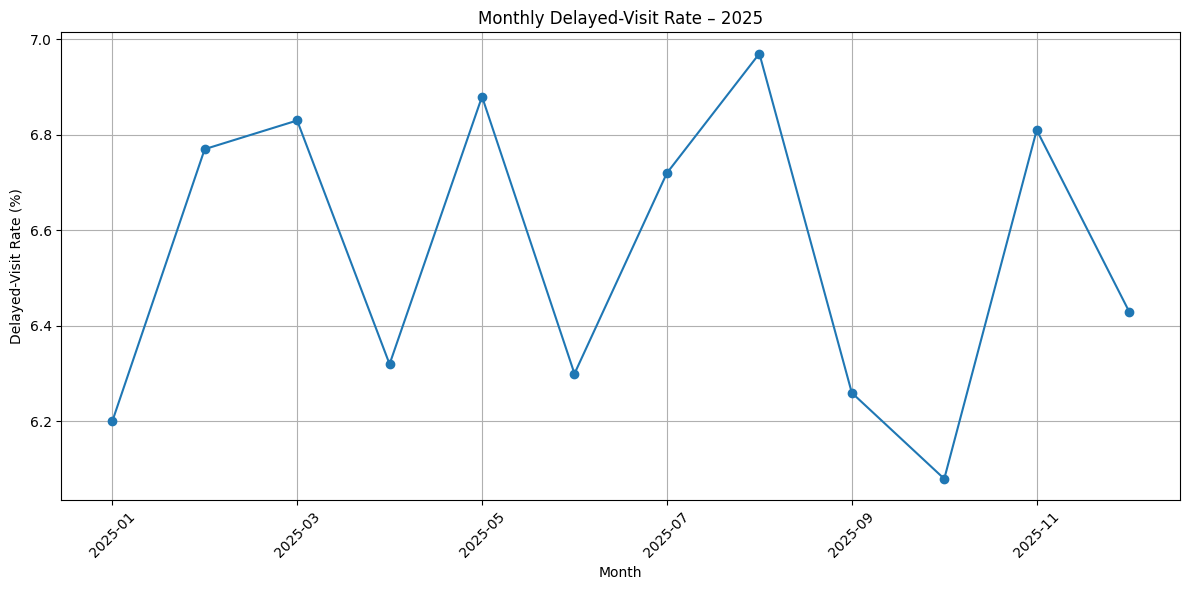

In [77]:
monthly_performance["delayed_visit_rate"].plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
    title="Monthly Delayed-Visit Rate – 2025",
    ylabel="Delayed-Visit Rate (%)",
    xlabel="Month"
)

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [78]:
highest_delay_month = monthly_performance["delayed_visit_rate"].idxmax()
lowest_delay_month = monthly_performance["delayed_visit_rate"].idxmin()

print("Highest delayed-visit month:", highest_delay_month)
print("Highest rate:", monthly_performance.loc[highest_delay_month, "delayed_visit_rate"], "%")

print("Lowest delayed-visit month:", lowest_delay_month)
print("Lowest rate:", monthly_performance.loc[lowest_delay_month, "delayed_visit_rate"], "%")

Highest delayed-visit month: 2025-08
Highest rate: 6.97 %
Lowest delayed-visit month: 2025-10
Lowest rate: 6.08 %


In [79]:
staff_vs_missed = location_report[
    ["missed_visit_rate", "staff_attendance_rate"]
].copy()

staff_vs_missed["missed_visit_rate"] = (
    staff_vs_missed["missed_visit_rate"] * 100
).round(2)

display(staff_vs_missed)

,missed_visit_rate,staff_attendance_rate
service_location,,
Corby,2.93,96.75
Daventry,2.44,96.82
Kettering,2.10,97.42
Milton Keynes North,3.02,96.27
Milton Keynes South,2.44,96.98
Northampton Central,3.12,96.16
Northampton East,2.59,97.09
Northampton West,2.27,97.37
Towcester,2.52,97.28


In [80]:
correlation = staff_vs_missed[
    "staff_attendance_rate"
].corr(
    staff_vs_missed["missed_visit_rate"]
)

print("Correlation:", round(correlation, 3))

Correlation: -0.906


In [81]:
risk_analysis = location_report.copy()

risk_analysis["missed_visit_pct"] = (
    risk_analysis["missed_visit_rate"] * 100
)

overall_missed_pct = missed_visit_rate * 100
overall_delayed_pct = delayed_visit_rate * 100

risk_analysis["risk_status"] = (
    (risk_analysis["missed_visit_pct"] > overall_missed_pct) &
    (risk_analysis["delayed_visit_rate"] > overall_delayed_pct)
)

display(
    risk_analysis[
        ["missed_visit_pct", "delayed_visit_rate", "risk_status"]
    ].sort_values("missed_visit_pct", ascending=False)
)

,missed_visit_pct,delayed_visit_rate,risk_status
service_location,,,
Northampton Central,3.118402,6.66,True
Milton Keynes North,3.016949,6.92,True
Corby,2.930641,5.97,False
Wellingborough,2.797877,7.20,True
Northampton East,2.590924,6.29,False
Towcester,2.517483,6.47,False
Daventry,2.439024,6.07,False
Milton Keynes South,2.436075,6.73,False
Northampton West,2.273465,6.55,False


In [82]:
priority_locations = risk_analysis[
    risk_analysis["risk_status"] == True
]

print("Number of priority locations:", len(priority_locations))

display(
    priority_locations[
        ["missed_visit_pct", "delayed_visit_rate"]
    ].round(2)
)

Number of priority locations: 3


,missed_visit_pct,delayed_visit_rate
service_location,,
Milton Keynes North,3.02,6.92
Northampton Central,3.12,6.66
Wellingborough,2.80,7.20


In [83]:
display(
    priority_locations[
        ["missed_visit_pct", "delayed_visit_rate"]
    ].round(2).sort_values(
        "missed_visit_pct",
        ascending=False
    )
)

,missed_visit_pct,delayed_visit_rate
service_location,,
Northampton Central,3.12,6.66
Milton Keynes North,3.02,6.92
Wellingborough,2.80,7.20


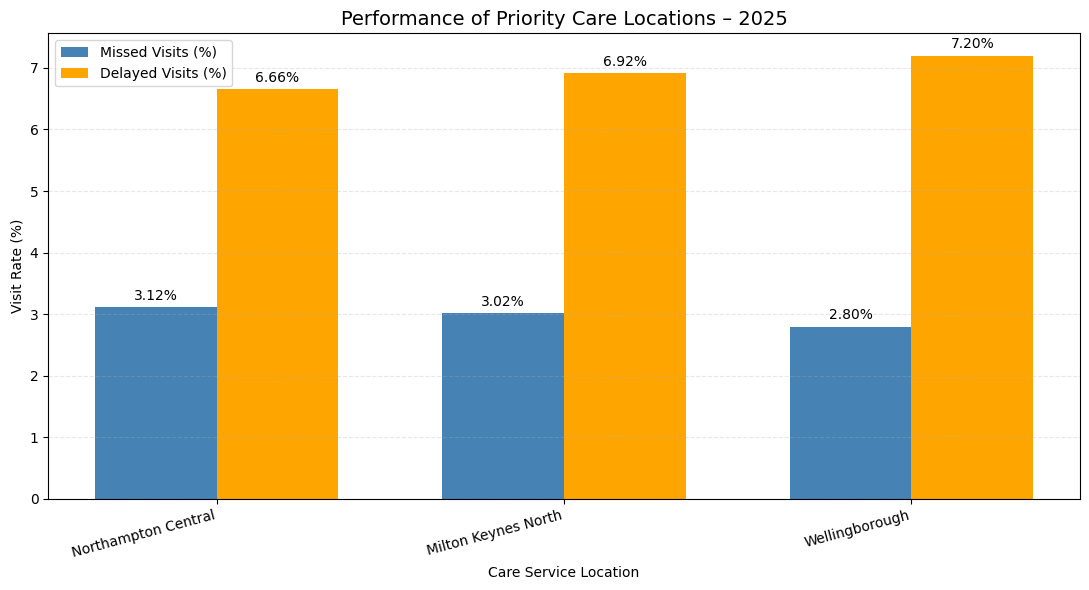

In [84]:
import matplotlib.pyplot as plt
import numpy as np

# Select the three priority locations
chart_data = priority_locations[
    ["missed_visit_pct", "delayed_visit_rate"]
].sort_values("missed_visit_pct", ascending=False)

# Set positions for the bars
x = np.arange(len(chart_data))
width = 0.35

# Create the chart
fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width/2,
    chart_data["missed_visit_pct"],
    width,
    label="Missed Visits (%)",
    color="steelblue"
)

ax.bar(
    x + width/2,
    chart_data["delayed_visit_rate"],
    width,
    label="Delayed Visits (%)",
    color="orange"
)

# Add titles and labels
ax.set_title(
    "Performance of Priority Care Locations – 2025",
    fontsize=14
)
ax.set_ylabel("Visit Rate (%)")
ax.set_xlabel("Care Service Location")

ax.set_xticks(x)
ax.set_xticklabels(chart_data.index, rotation=15, ha="right")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Display percentages above bars
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

In [85]:
plt.tight_layout()
plt.savefig(
    "priority_care_locations_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>